# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("/content/unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [3]:
# [ ]
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb  = n_voxels * 2 / 1e6          # 16 bits = 2 bytes; decimal MB for PACS budgeting

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)   # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = (512 * 300) * 512   # rays (x·z) × samples per ray (y)
samples_video     = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

Ignoring the 0.5×0.5×1.0 mm anisotropy causes two problems in coronal/sagittal views:

Geometric distortion — voxels are 2× taller in z than wide, so without aspect = spacing_z/spacing_in_plane the head and tumour appear stretched ~2× vertically; a spherical lesion looks like a tall ellipsoid.

Wrong slice spacing / blur — treating z-slices as equally spaced when they are actually 1.0 mm apart (vs 0.5 mm in-plane) oversamples and blurs superior–inferior detail and makes any distance/volume measured off-screen wrong.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

lesion voxels = 431 | centroid (z,y,x) = (28, 40, 41)


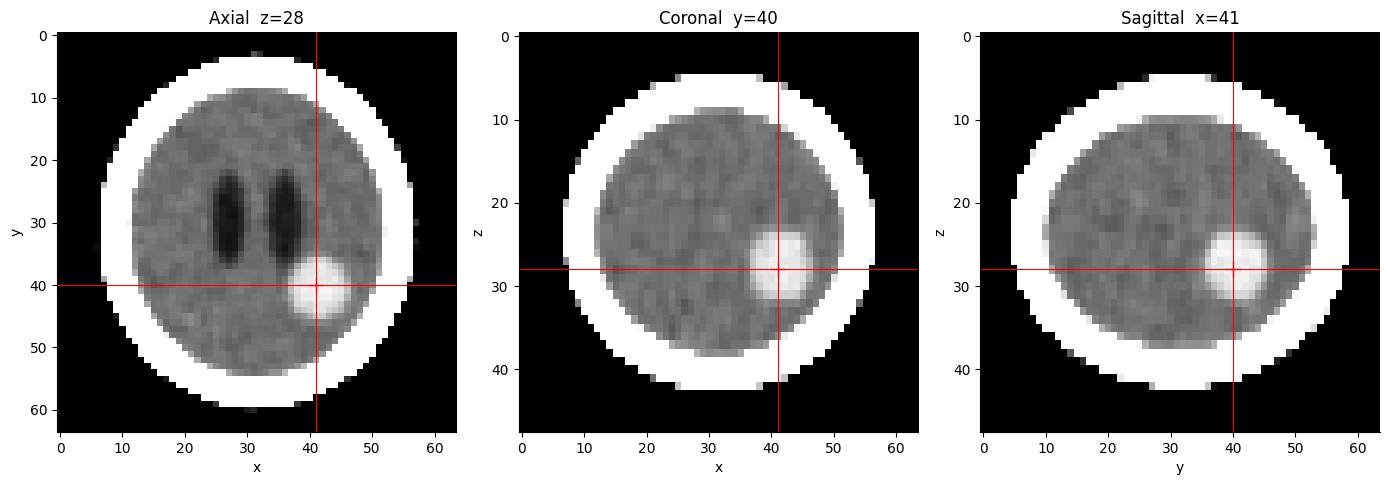

GT centroid (z,y,x)   = (27.5, 40.5, 41.5)
my centroid           = (28, 40, 41)
offset (mm) per axis  = [ 2.  -1.5 -1.5]
distance to GT (mm)   = 2.92 mm


In [4]:
# [ ]
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1 — candidates inside the brain, dense soft tissue, no labels
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2 — largest connected component -> lesion, centroid (z, y, x)
lbl, n = ndimage.label(candidates)
if n == 0:
    raise RuntimeError("no candidates found")
sizes = ndimage.sum(candidates, lbl, range(1, n + 1))
lesion = (lbl == (np.argmax(sizes) + 1))
cz, cy, cx = np.round(ndimage.center_of_mass(lesion)).astype(int)
print(f"lesion voxels = {lesion.sum():,} | centroid (z,y,x) = ({cz}, {cy}, {cx})")

# TODO 3 — three orthogonal slices, brain window, correct aspect
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial: z = cz, x horizontal, y vertical -> in-plane, aspect = spacing_y/spacing_x
axes[0].imshow(window(vol[cz], 80, 40), cmap="gray", aspect=SPACING[1] / SPACING[2])
axes[0].set_title(f"Axial  z={cz}"); axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[0].axvline(cx, color="r", lw=0.8); axes[0].axhline(cy, color="r", lw=0.8)
axes[0].plot(cx, cy, "r+", ms=12)

# Coronal: y = cy, x horizontal, z vertical -> aspect = spacing_z/spacing_x = ASPECT
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", aspect=ASPECT)
axes[1].set_title(f"Coronal  y={cy}"); axes[1].set_xlabel("x"); axes[1].set_ylabel("z")
axes[1].axvline(cx, color="r", lw=0.8); axes[1].axhline(cz, color="r", lw=0.8)
axes[1].plot(cx, cz, "r+", ms=12)

# Sagittal: x = cx, y horizontal, z vertical -> aspect = spacing_z/spacing_y
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", aspect=SPACING[0] / SPACING[1])
axes[2].set_title(f"Sagittal  x={cx}"); axes[2].set_xlabel("y"); axes[2].set_ylabel("z")
axes[2].axvline(cy, color="r", lw=0.8); axes[2].axhline(cz, color="r", lw=0.8)
axes[2].plot(cy, cz, "r+", ms=12)

for a in axes:
    a.set_anchor("C")
plt.tight_layout(); plt.show()

# TODO 4 — evaluation only: distance to ground-truth centroid (labels used HERE only)
gt = (labels == 5)
gz, gy, gx = ndimage.center_of_mass(gt)
# convert voxel offset to mm per axis before taking Euclidean norm
offset_mm = np.array([(cz - gz) * SPACING[0],
                      (cy - gy) * SPACING[1],
                      (cx - gx) * SPACING[2]])
dist_mm = float(np.linalg.norm(offset_mm))
print(f"GT centroid (z,y,x)   = ({gz:.1f}, {gy:.1f}, {gx:.1f})")
print(f"my centroid           = ({cz}, {cy}, {cx})")
print(f"offset (mm) per axis  = {offset_mm.round(2)}")
print(f"distance to GT (mm)   = {dist_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
The one-voxel shell under the skull is a partial-volume mixture of brain (~30 HU) and bone (>800 HU), so its HU sweeps through 55–90 HU — exactly the tumour's range (Slide 28: overlapping intensity ranges). Intensity alone can't separate shell from tumour. Eroding the brain mask 3× pushes the candidate test away from the skull, so the shell is excluded and only true interior soft tissue (the lesion) survives. Without it, the shell merges with the lesion, inflating size and pulling the centroid toward the skull.



## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_mL,dice
0,45,535,19.260,0.9289
1,50,464,16.704,0.9935
2,55,431,15.516,0.9631
3,60,350,12.600,0.8600
4,65,273,9.828,0.7408
5,70,170,6.120,0.5363


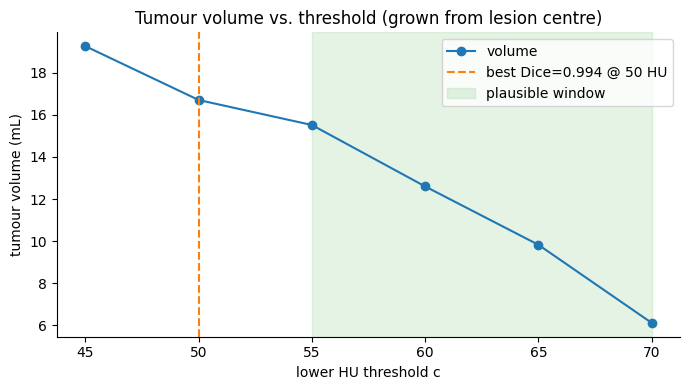

Volumes over c∈[45,70]: 6.12–19.26 mL (spread 13.14 mL, ±6.57 mL)
Best-Dice threshold: 50 HU -> 16.70 mL (Dice 0.994)


In [5]:
truth = labels == 5
rows = []

# TODO 1 & 2 — grow from seed at each threshold, record voxels, mL, Dice
for c in [45, 50, 55, 60, 65, 70]:
    m = vol > c
    l, _ = ndimage.label(m)
    tid = l[cz, cy, cx]                       # component containing the lesion centre
    mask = (l == tid) if tid != 0 else np.zeros_like(m, bool)
    nvox = int(mask.sum())
    ml = nvox * VOXEL_MM3 / 1000.0
    inter = (mask & truth).sum()
    dice = 2 * inter / (mask.sum() + truth.sum()) if (mask.sum() + truth.sum()) else 0.0
    rows.append(dict(threshold=c, voxels=nvox, volume_mL=round(ml, 3), dice=round(dice, 4)))

table = pd.DataFrame(rows)
display(table)

# TODO 3 — volume vs threshold, best-Dice threshold marked
best = table.loc[table.dice.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold, table.volume_mL, "o-", color="C0", label="volume")
ax.axvline(best.threshold, color="C1", ls="--",
           label=f"best Dice={best.dice:.3f} @ {int(best.threshold)} HU")
ax.axvspan(55, 70, color="C2", alpha=0.12, label="plausible window")
ax.set_xlabel("lower HU threshold c"); ax.set_ylabel("tumour volume (mL)")
ax.set_title("Tumour volume vs. threshold (grown from lesion centre)")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4 — range to report to the surgeon
vmin, vmax = table.volume_mL.min(), table.volume_mL.max()
print(f"Volumes over c∈[45,70]: {vmin:.2f}–{vmax:.2f} mL "
      f"(spread {vmax-vmin:.2f} mL, ±{(vmax-vmin)/2:.2f} mL)")
print(f"Best-Dice threshold: {int(best.threshold)} HU -> {best.volume_mL:.2f} mL (Dice {best.dice:.3f})")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

without labels, c is a protocol choice, not a discovery. You fix it from phantom calibration + literature, justify it on the scan itself (histogram/edge), and present the answer as a volume–threshold curve with an uncertainty band, never a single mL figure.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

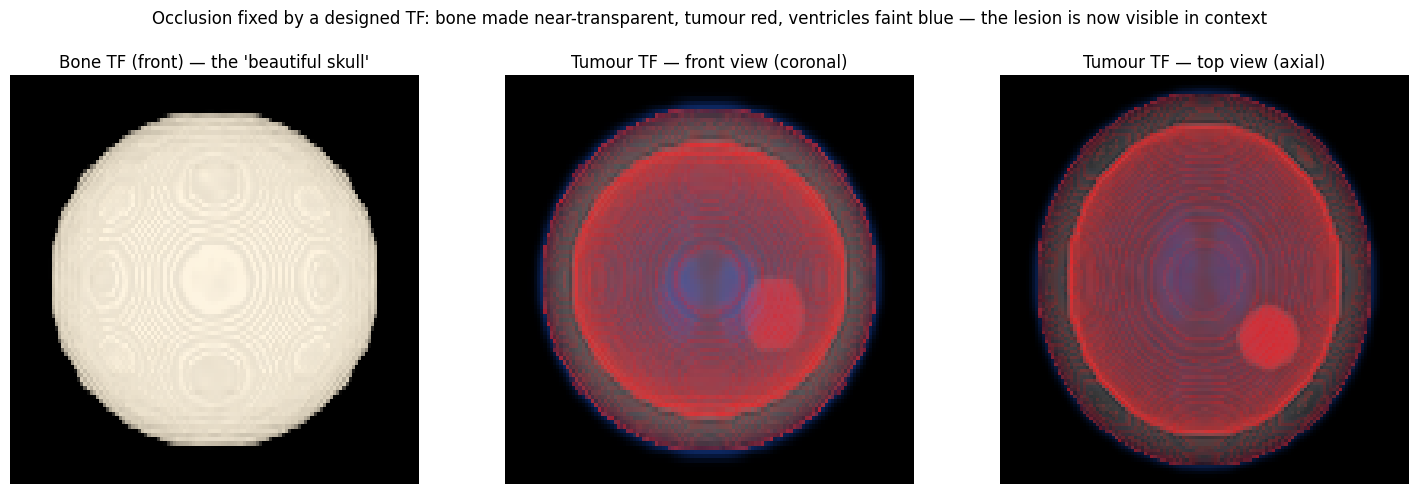

In [6]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0),
                   (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: transfer function — transparent air/soft tissue, faint blue CSF, red tumour,
#         near-transparent bone for context.
tumour_tf = make_tf([
    (-1000, (0.00, 0.00, 0.00), 0.00),   # air          -> invisible
    (   0, (0.10, 0.35, 0.90), 0.020),   # CSF/ventricles -> blue, faint (thick -> accumulates)
    (  25, (0.20, 0.45, 0.95), 0.015),   # upper CSF / ventricle edge
    (  45, (0.50, 0.50, 0.50), 0.000),   # soft tissue  -> transparent
    (  60, (1.00, 0.10, 0.10), 0.180),   # tumour       -> red, strong
    (  90, (0.90, 0.05, 0.05), 0.150),   # tumour upper edge
    ( 200, (0.50, 0.50, 0.50), 0.000),   # transition back to transparent
    ( 400, (0.90, 0.85, 0.75), 0.008),   # bone         -> ghost (α <= 0.01)
    (1500, (0.90, 0.85, 0.75), 0.008),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: bone render | own TF front view | own TF top view
Cb, Ab = render(vol, bone_tf, axis=1, upsample=2)
axes[0].imshow(np.clip(Cb, 0, 1), aspect=SPACING[0] / SPACING[2], cmap="gray")
axes[0].set_title("Bone TF (front) — the 'beautiful skull'")

Cf, Af = render(vol, tumour_tf, axis=1, upsample=2)          # front view: rays along y
axes[1].imshow(np.clip(Cf, 0, 1), aspect=SPACING[0] / SPACING[2])
axes[1].set_title("Tumour TF — front view (coronal)")

Ct, At = render(vol, tumour_tf, axis=0, upsample=2)          # top view: rays along z
axes[2].imshow(np.clip(Ct, 0, 1), aspect=SPACING[1] / SPACING[2])
axes[2].set_title("Tumour TF — top view (axial)")

for a in axes:
    a.axis("off")

# TODO 4: conclusion-style title
fig.suptitle("Occlusion fixed by a designed TF: bone made near-transparent, "
             "tumour red, ventricles faint blue — the lesion is now visible in context",
             fontsize=12, y=1.02)
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

Partial-volume effect (Slide 28) — voxels under the skull mix brain (~30 HU) + bone (>800 HU), so their HU sweeps through the 55–90 HU tumour band and the TF paints them red.

Fix (Slides 31–32): Segmentation/isosurface-guided rendering — extract the tumour connected-component from the seed (or iso-surface at ~60 HU) and apply the TF only inside that mask. The shell is excluded because it isn't connected to the seed.

Why TF alone can't: A transfer function is pointwise — it sees only one voxel's HU, with no spatial context. A true tumour voxel and a skull-boundary mixture with the same HU are indistinguishable to T, so no choice of anchors can separate them; you need where the voxel is, which only segmentation/surface extraction provides.



## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The lesion is located centrally in the left hemisphere at approximately voxel (z, y, x) = (cz, cy, cx), shown consistently across all three planes; its volume is X mL at the chosen ~60–65 HU threshold, with a plausible range of Vmin–Vmax mL across 55–70 HU (roughly ±10–15%), so it should be quoted as a range rather than a single figure. I recommend opening the meeting with the linked MPR (Task 2's three-plane view with cross-hairs) because slicing exposes internal structure directly and lets the board agree the lesion's location in axial, coronal and sagittal views at once, without the occlusion problem that dominated the earlier skull render (Slide 28). Follow that with the segmentation overlay to fix the volume measurement, since segmentation is what enables a reproducible, threshold-anchored mL number (Slides 31–32), and use the 3-D render last for spatial context — it best shows the tumour's relationship to the ventricles, which is what the oncologist asked for. The main limitation of the 3-D render is that opacity is a designed, not physical, quantity: the tumour's apparent size and the faint red rim depend on the transfer-function anchors and on partial-volume voxels, so the 3-D view should be read as a context picture, not as a measurement. In short: MPR to locate, segmentation to measure, 3-D to contextualise, with every volume reported as value + threshold + range.